In [1]:
# Setup
import glob
import json

import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt

RESULTS_DIR = "Results"
METRIC = "scaled MAE (all)"
BASELINE = "last-value baseline"
ACCURACY_COLUMNS = ["MAE", "scaled MAE (nominal)", "scaled MAE (off nominal)", "scaled MAE (all)",
                    "baseline (nominal)", "baseline (off nominal)", "baseline (all)"]


In [2]:
# Load results
def read_group(group):
    values = {}
    for col in group:
        values[col] = group[col][()]
    return values


tables = {}
forecasts = {}
settings = {}
for path in sorted(glob.glob(f"{RESULTS_DIR}/setpointforecast_*.h5")):
    with h5py.File(path, "r") as f:
        model = f.attrs["model"]
        settings[model] = json.loads(f.attrs["settings"])

        table = pd.DataFrame(index=f["variable"].asstr()[()])
        table["description"] = f["description"].asstr()[()]
        for name in ACCURACY_COLUMNS:
            table[name] = f[name][()]
        tables[model] = table

        forecasts[model] = {
            "time_h": f["time_h"][()],
            "off_nominal": f["off_nominal"][()],
            "context_time_h": f["context_time_h"][()],
            "forecast": read_group(f["forecast"]),
            "lower": read_group(f["lower"]),
            "upper": read_group(f["upper"]),
            "actual": read_group(f["actual"]),
            "context": read_group(f["context"]),
        }

MODELS = list(tables)
print(f"Loaded {len(MODELS)} models: {', '.join(MODELS)}")

# Check that all models used the same data and forecast window
for key in ["data_file", "event_index", "split", "horizon"]:
    values = set()
    for model in MODELS:
        values.add(str(settings[model][key]))
    if len(values) > 1:
        print(f"Warning: the models differ in {key}: {', '.join(sorted(values))}")

pd.DataFrame(settings).T


Loaded 3 models: ARX + Ridge, Chronos-2, TimesFM 3.0


,data_file,event_index,split,horizon,future_covariates,past_only_covariates
ARX + Ridge,tep_sp_spaced_6min_noisy.h5,67,5874,200,"[sp_5, sp_7, sp_8, sp_11, sp_13, sp_14, sp_15,...",[]
Chronos-2,tep_sp_spaced_6min_noisy.h5,67,5874,200,"[sp_5, sp_7, sp_8, sp_11, sp_13, sp_14, sp_15,...",[]
TimesFM 3.0,tep_sp_spaced_6min_noisy.h5,67,5874,200,"[sp_5, sp_7, sp_8, sp_11, sp_13, sp_14, sp_15,...",[]


In [3]:
# Scores per variable (xmeas_1 ... xmv_12)
first = MODELS[0]
descriptions = tables[first]["description"]

scores = pd.DataFrame(index=tables[first].index)
for model in MODELS:
    scores[model] = tables[model][METRIC]
scores[BASELINE] = tables[first][METRIC.replace("scaled MAE", "baseline")]
scores = scores.dropna()

ALL = MODELS + [BASELINE]
COLORS = {}
for i, model in enumerate(MODELS):
    COLORS[model] = f"C{i}"
COLORS[BASELINE] = "gray"

table = scores.copy()
table.insert(0, "description", descriptions)
print(f"{METRIC} per variable, lower is better")
table.round(3)


scaled MAE (all) per variable, lower is better


,description,ARX + Ridge,Chronos-2,TimesFM 3.0,last-value baseline
xmeas_1,A feed (kscmh),0.554,0.414,0.486,0.809
xmeas_2,D feed (kg/h),0.697,0.773,0.745,1.039
xmeas_3,E feed (kg/h),0.495,0.487,0.524,0.698
xmeas_4,A and C feed (kscmh),0.529,0.449,0.568,0.884
xmeas_5,Recycle flow (kscmh),0.736,0.802,0.841,1.086
xmeas_6,Reactor feed rate (kscmh),0.773,0.752,0.916,1.477
xmeas_7,Reactor pressure (kPa),0.254,0.268,0.504,1.296
xmeas_8,Reactor level (%),0.617,0.551,0.678,0.840
xmeas_9,Reactor temperature (C),0.257,0.263,0.260,0.264
xmeas_10,Purge rate (kscmh),0.383,0.421,0.339,1.412


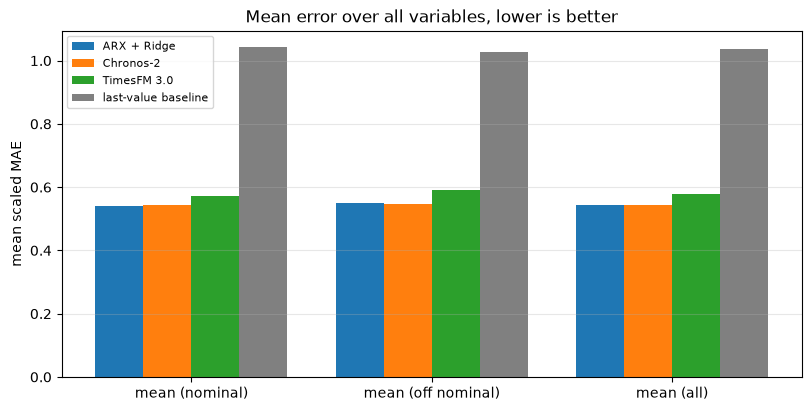

,mean (nominal),mean (off nominal),mean (all),median (all),best on (variables)
model,,,,,
Chronos-2,0.543,0.547,0.545,0.474,19
ARX + Ridge,0.541,0.550,0.545,0.537,22
TimesFM 3.0,0.571,0.590,0.579,0.520,11
last-value baseline,1.043,1.028,1.036,0.962,0


In [4]:
# Summary
best_model = scores[ALL].idxmin(axis=1)   # model with the lowest error for each variable

rows = []
for model in ALL:
    if model == BASELINE:
        table, prefix = tables[first], "baseline"
    else:
        table, prefix = tables[model], "scaled MAE"
    rows.append({
        "model": model,
        "mean (nominal)": table[f"{prefix} (nominal)"].mean(),
        "mean (off nominal)": table[f"{prefix} (off nominal)"].mean(),
        "mean (all)": table[f"{prefix} (all)"].mean(),
        "median (all)": table[f"{prefix} (all)"].median(),
        "best on (variables)": (best_model == model).sum(),
    })
summary = pd.DataFrame(rows).set_index("model").sort_values("mean (all)")

# Mean error per model, for the nominal, off-nominal and all samples
phases = ["mean (nominal)", "mean (off nominal)", "mean (all)"]
bar_width = 0.8 / len(ALL)
x = np.arange(len(phases))

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for i, model in enumerate(ALL):
    shift = (i - (len(ALL) - 1) / 2) * bar_width
    ax.bar(x + shift, summary.loc[model, phases], width=bar_width, color=COLORS[model], label=model)
ax.set_xticks(x)
ax.set_xticklabels(phases)
ax.set_ylabel("mean scaled MAE")
ax.set_title("Mean error over all variables, lower is better")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, axis="y")
plt.show()

summary.round(3)


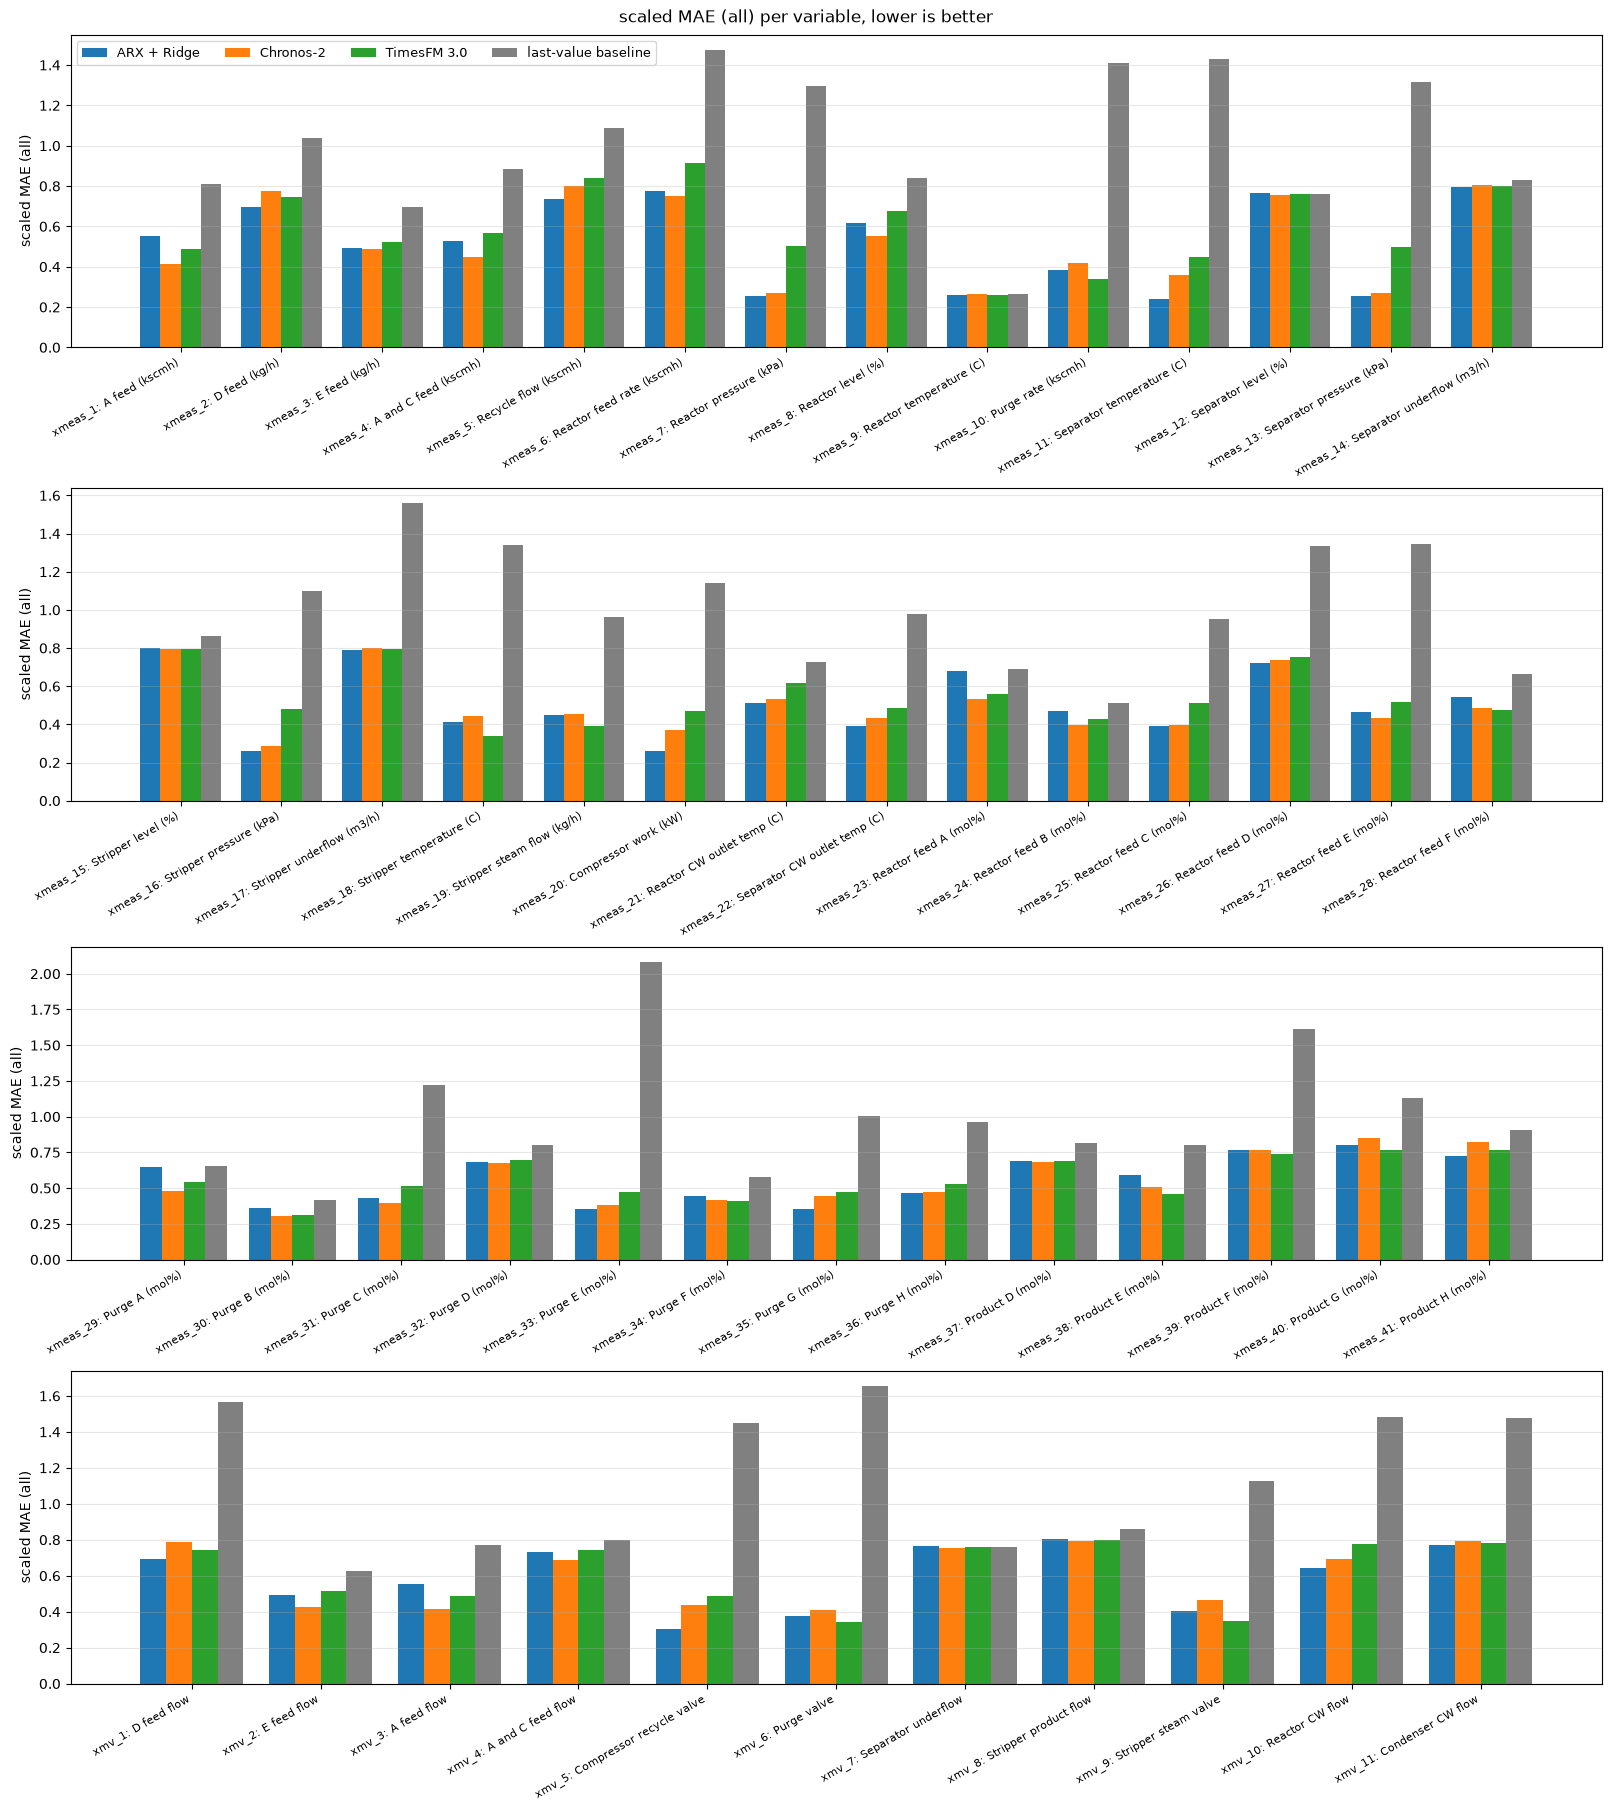

In [5]:
# Error per variable, models side by side
xmeas = [v for v in scores.index if v.startswith("xmeas")]
xmv = [v for v in scores.index if v.startswith("xmv")]
panels = [xmeas[0:14], xmeas[14:28], xmeas[28:], xmv]

bar_width = 0.8 / len(ALL)
fig, axes = plt.subplots(len(panels), 1, figsize=(16, 4.5 * len(panels)), layout="constrained")
for ax, names in zip(axes, panels):
    x = np.arange(len(names))
    for i, model in enumerate(ALL):
        shift = (i - (len(ALL) - 1) / 2) * bar_width
        ax.bar(x + shift, scores.loc[names, model], width=bar_width, color=COLORS[model], label=model)

    labels = []
    for v in names:
        labels.append(f"{v}: {descriptions[v]}")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30, ha="right", fontsize=8)
    ax.set_ylabel(METRIC)
    ax.grid(alpha=0.3, axis="y")
axes[0].legend(fontsize=9, ncols=len(ALL))
fig.suptitle(f"{METRIC} per variable, lower is better")
plt.show()


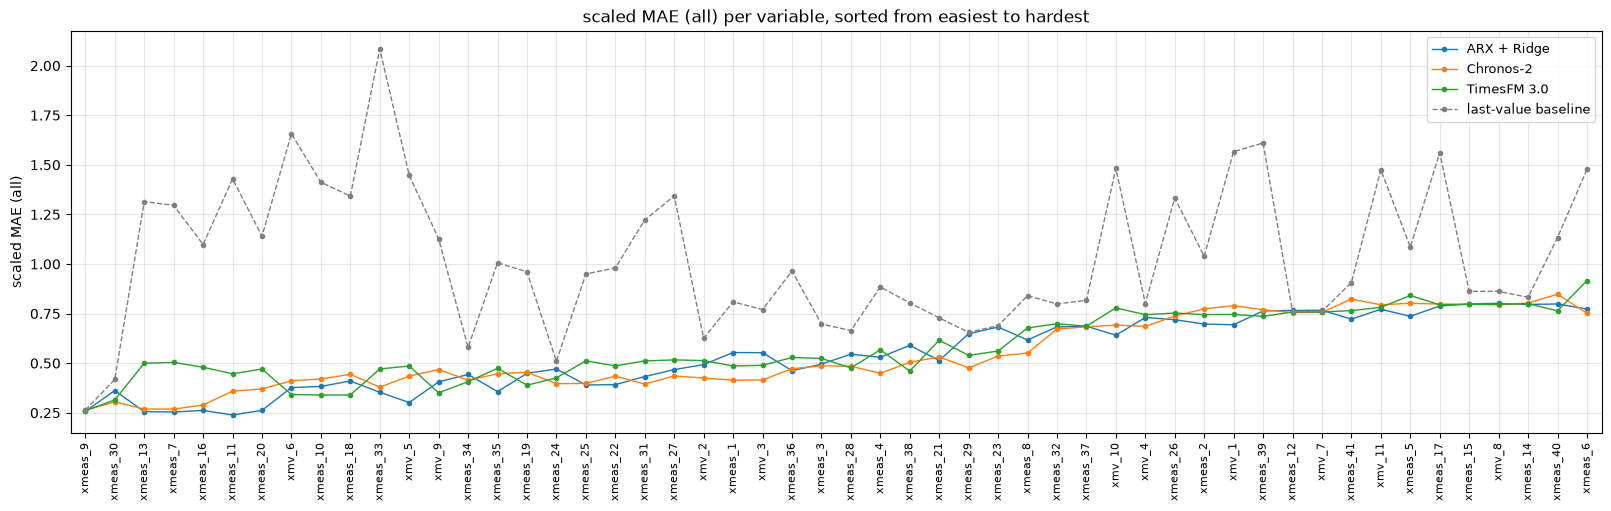

,description,ARX + Ridge,Chronos-2,TimesFM 3.0,last-value baseline,best model
xmeas_9,Reactor temperature (C),0.257,0.263,0.260,0.264,ARX + Ridge
xmeas_30,Purge B (mol%),0.362,0.305,0.315,0.418,Chronos-2
xmeas_13,Separator pressure (kPa),0.256,0.269,0.500,1.314,ARX + Ridge
xmeas_7,Reactor pressure (kPa),0.254,0.268,0.504,1.296,ARX + Ridge
xmeas_16,Stripper pressure (kPa),0.262,0.289,0.480,1.098,ARX + Ridge
xmeas_11,Separator temperature (C),0.239,0.359,0.446,1.429,ARX + Ridge
xmeas_20,Compressor work (kW),0.262,0.370,0.470,1.141,ARX + Ridge
xmv_6,Purge valve,0.377,0.411,0.342,1.656,TimesFM 3.0
xmeas_10,Purge rate (kscmh),0.383,0.421,0.339,1.412,TimesFM 3.0
xmeas_18,Stripper temperature (C),0.410,0.444,0.340,1.342,TimesFM 3.0


In [6]:
# Variables sorted by error
order = scores[MODELS].mean(axis=1).sort_values().index
sorted_scores = scores.loc[order, ALL]
x = np.arange(len(order))

fig, ax = plt.subplots(figsize=(16, 5), layout="constrained")
for model in ALL:
    if model == BASELINE:
        style = "--"
    else:
        style = "-"
    ax.plot(x, sorted_scores[model], style, marker="o", ms=3, lw=1, color=COLORS[model], label=model)
ax.set_xticks(x)
ax.set_xticklabels(order, rotation=90, fontsize=8)
ax.set_xlim(-0.5, len(order) - 0.5)
ax.set_ylabel(METRIC)
ax.set_title(f"{METRIC} per variable, sorted from easiest to hardest")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.show()

table = sorted_scores.copy()
table.insert(0, "description", descriptions)
table["best model"] = best_model
table.round(3)


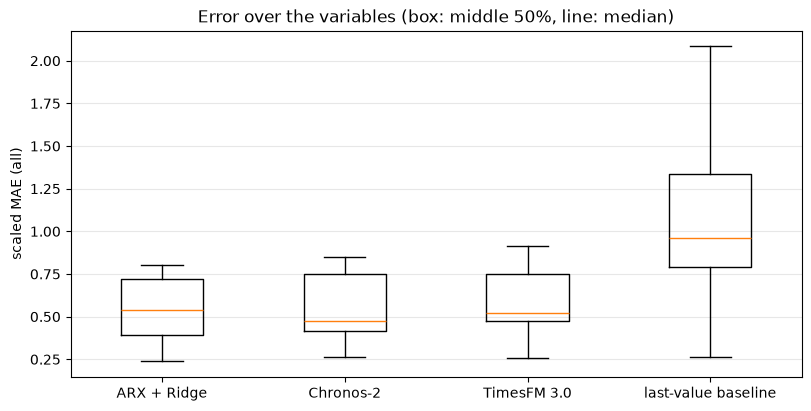

In [7]:
# Spread of the error over the variables
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.boxplot([scores[model] for model in ALL], tick_labels=ALL)
ax.set_ylabel(METRIC)
ax.set_title("Error over the variables (box: middle 50%, line: median)")
ax.grid(alpha=0.3, axis="y")
plt.show()


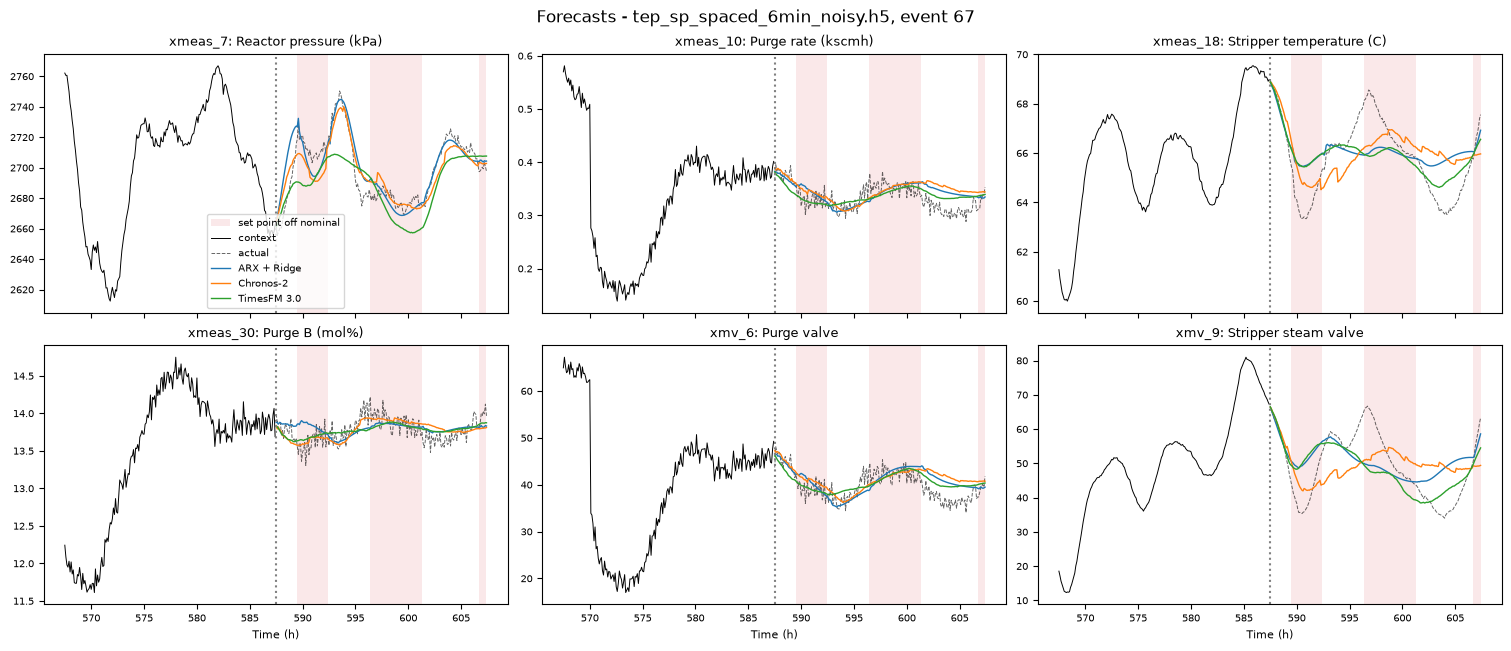

In [8]:
# Forecasts of a few variables, all models in one plot
PLOT_VARIABLES = ["xmeas_7", "xmeas_10", "xmeas_18", "xmeas_30", "xmv_6", "xmv_9"]
NCOLS = 3

ref = forecasts[first]
nrows = int(np.ceil(len(PLOT_VARIABLES) / NCOLS))
fig, axes = plt.subplots(nrows, NCOLS, figsize=(5 * NCOLS, 3.2 * nrows), sharex=True, squeeze=False,
                         layout="constrained")
for ax, col in zip(axes.ravel(), PLOT_VARIABLES):
    ax.fill_between(ref["time_h"], 0, 1, where=ref["off_nominal"], color="tab:red", alpha=0.1,
                    transform=ax.get_xaxis_transform(), step="post", lw=0, label="set point off nominal")
    ax.plot(ref["context_time_h"], ref["context"][col], color="black", lw=0.7, label="context")
    ax.plot(ref["time_h"], ref["actual"][col], color="black", lw=0.7, ls="--", alpha=0.6, label="actual")
    for model in MODELS:
        ax.plot(forecasts[model]["time_h"], forecasts[model]["forecast"][col], color=COLORS[model], lw=1,
                label=model)
    ax.axvline(ref["time_h"][0], color="gray", ls=":")
    ax.set_title(f"{col}: {descriptions[col]}", fontsize=9)
    ax.tick_params(labelsize=7)
for ax in axes.ravel()[len(PLOT_VARIABLES):]:
    ax.axis("off")
for ax in axes[-1]:
    ax.set_xlabel("Time (h)", fontsize=8)
axes[0, 0].legend(fontsize=7)
fig.suptitle(f"Forecasts - {settings[first]['data_file']}, event {settings[first]['event_index']}")
plt.show()


Saved Figures/setpointforecast_compare_article_event67_intervals_band.pdf and .png


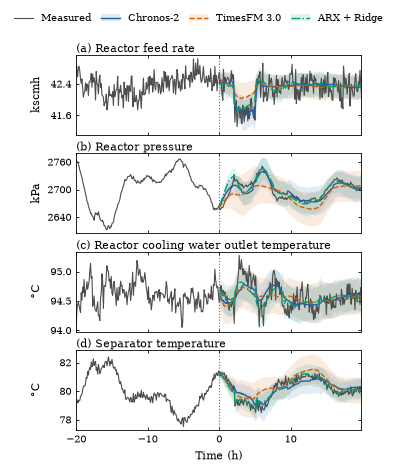

In [9]:
# Article figure: all models in one plot
import os
import re
from matplotlib.legend_handler import HandlerTuple
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

ARTICLE_COLUMNS = ["xmeas_6", "xmeas_7", "xmeas_21", "xmeas_11"]
ARTICLE_MODELS = ["Chronos-2", "TimesFM 3.0", "ARX + Ridge"]   # model names as saved in the results files
SHOW_INTERVALS = True    # 10-90% interval of every model, in the colour of its forecast
INTERVAL_STYLE = "band"  # "band": light band, "fill": light band with thin edges, "lines": dashed edges only
INTERVAL_ALPHA = 0.12    # band opacity, low so that overlapping bands stay light
EDGE_STYLE = {"fill": {"lw": 0.4}, "lines": {"lw": 0.6, "ls": (0, (2, 1.5))}}
EVENT_INDEX = settings[ARTICLE_MODELS[0]]["event_index"]
FIGURE_NAME = f"setpointforecast_compare_article_event{EVENT_INDEX}" + (f"_intervals_{INTERVAL_STYLE}" if SHOW_INTERVALS else "")
FIGURE_DIR = "Figures"
MEASURED_COLOR = "0.3"   # grey of the measured line
ARTICLE_COLORS = ["#1f5fa8", "#d55e00", "#009e73", "#cc79a7"]   # colour-blind safe, one per model
ARTICLE_LINESTYLES = ["-", "--", "-.", ":"]                       # also readable in black and white
ARTICLE_STYLE = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.titlesize": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
}


def split_label(label):
    name, unit = re.fullmatch(r"(.*?)\s*\((.*)\)", label).groups()
    name = re.sub(r" temp$", " temperature", name.replace("CW", "cooling water"))
    return name, {"C": "°C", "m3/h": "m³/h"}.get(unit, unit)


missing = [model for model in ARTICLE_MODELS if model not in forecasts]
if missing:
    raise ValueError(f"No results for {', '.join(missing)} (loaded: {', '.join(MODELS)})")
for key in ["data_file", "split", "horizon"]:
    if len({str(settings[model][key]) for model in ARTICLE_MODELS}) > 1:
        raise ValueError(f"The models differ in {key}, run them on the same forecast window first")

ref = forecasts[ARTICLE_MODELS[0]]
t0 = ref["time_h"][0]   # forecast start becomes time 0
measured_t = np.concatenate([ref["context_time_h"], ref["time_h"]]) - t0
with plt.rc_context(ARTICLE_STYLE):
    fig, axes = plt.subplots(len(ARTICLE_COLUMNS), 1, figsize=(3.5, 1.1 * len(ARTICLE_COLUMNS)), sharex=True)
    for letter, ax, col in zip("abcdefgh", axes, ARTICLE_COLUMNS):
        name, unit = split_label(descriptions[col])
        ax.plot(measured_t, np.concatenate([ref["context"][col], ref["actual"][col]]), color=MEASURED_COLOR, lw=0.8,
                label="Measured")
        for model, color, ls in zip(ARTICLE_MODELS, ARTICLE_COLORS, ARTICLE_LINESTYLES):
            fc = forecasts[model]
            if SHOW_INTERVALS:
                t = fc["time_h"] - t0
                if INTERVAL_STYLE in ["band", "fill"]:
                    ax.fill_between(t, fc["lower"][col], fc["upper"][col], color=color, alpha=INTERVAL_ALPHA, lw=0,
                                    zorder=1)
                for bound in ([fc["lower"][col], fc["upper"][col]] if INTERVAL_STYLE in EDGE_STYLE else []):
                    ax.plot(t, bound, color=color, alpha=0.8, zorder=2, **EDGE_STYLE[INTERVAL_STYLE])
            ax.plot(fc["time_h"] - t0, fc["forecast"][col], color=color, ls=ls, lw=1.0, zorder=3, label=model)
        ax.axvline(0, color="0.4", ls=":", lw=0.8)
        ax.set_title(f"({letter}) {name}", loc="left", pad=2)
        ax.set_ylabel(unit)
        ax.yaxis.set_major_locator(MaxNLocator(3))
        ax.ticklabel_format(axis="y", useOffset=False)
        ax.margins(x=0)
    axes[-1].set_xlabel("Time (h)")
    fig.align_ylabels(axes)
    handles, labels = axes[0].get_legend_handles_labels()
    if SHOW_INTERVALS and INTERVAL_STYLE in ["band", "fill"]:   # each forecast line drawn over a patch of its band colour
        handles = handles[:1] + [(Patch(color=color, alpha=INTERVAL_ALPHA, lw=0), h)
                                 for color, h in zip(ARTICLE_COLORS, handles[1:])]
    fig.tight_layout(h_pad=0.3)
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=len(labels), frameon=False,
               handlelength=2.0, columnspacing=1.0, handler_map={tuple: HandlerTuple(ndivide=1, pad=0)})

    os.makedirs(FIGURE_DIR, exist_ok=True)
    for ext in ["pdf", "png"]:
        fig.savefig(f"{FIGURE_DIR}/{FIGURE_NAME}.{ext}", dpi=600, bbox_inches="tight")
print(f"Saved {FIGURE_DIR}/{FIGURE_NAME}.pdf and .png")